Savannah Fox, Jake MacMillian, Paola Quiroga, Sreekaanth Srinivasan, Keshav Bhakta

## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

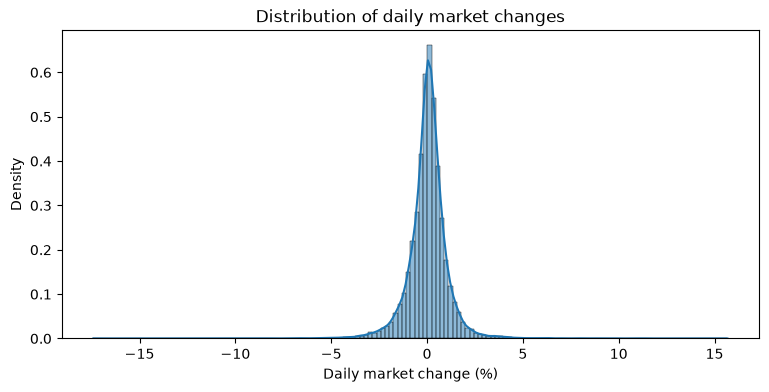

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

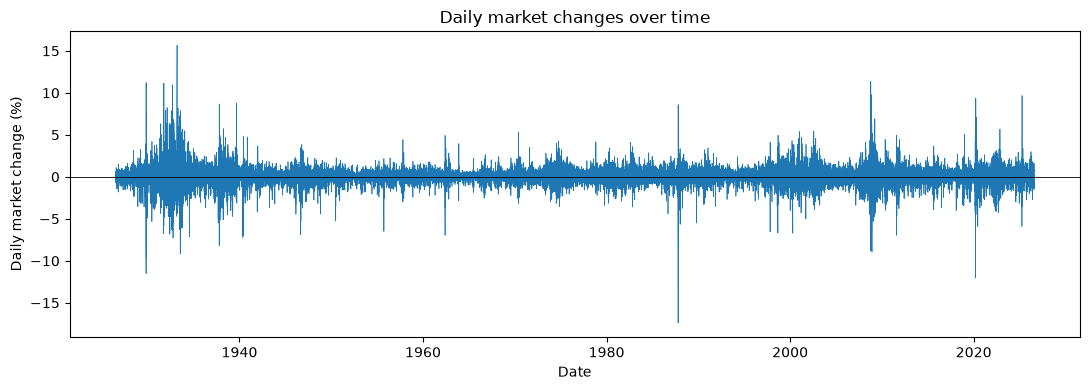

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# two categories: UP for values greater than 0, and Down (and flat)for values less than or equal to 0.
threshold = 0
df['state'] = np.where(df['market_return_pct'] > threshold, 'Up', 'Down')
#variables in your dataframe to capture the current and next value of the market return percentage in terms of up or down
df['current_state'] = df['state']
df['next_state'] = df['state'].shift(-1)
# drop the last row since it will have a NaN value for the next_state
df = df.dropna(subset=['next_state']).reset_index(drop=True)

In [5]:
#joint PMF and marginals
joint_PMF = pd.crosstab(df['current_state'], df['next_state'], normalize=True)
print(joint_PMF)

next_state         Down        Up
current_state                    
Down           0.224720  0.228142
Up             0.228142  0.318996


In [6]:
#marginal PMF for current_state
marginal_PMF_current = joint_PMF.sum(axis=1)
print(marginal_PMF_current)

current_state
Down    0.452862
Up      0.547138
dtype: float64


In [7]:
#marginal PMF for next_state
marginal_PMF_next = joint_PMF.sum(axis=0)
print(marginal_PMF_next)

next_state
Down    0.452862
Up      0.547138
dtype: float64


In [8]:
#conditional PMF (Joint PMF / marginal PMF )
conditional_PMF = joint_PMF.div(marginal_PMF_current, axis=0)
print(conditional_PMF)

next_state         Down        Up
current_state                    
Down           0.496221  0.503779
Up             0.416974  0.583026


- Are up transitions more or less common than down transitions? 

Up transitions are more common than down transition because from the current state of down there is a .503779 probability of transitioning to up  compared to a 0.496221 probabilty fo transitioning to down. For the Up current state it also has a higher probability fo transitioning to up than down at a proabaility of 0.583026 to the down probabilyt of 0.416974. We can also see this in the marginal PMF for the next state which shows that the marginal probability of being up  the next day is 0.547138 which is larger than the down state probability which is 0.452862.

- Are you more likely to transition to an Up day from a Down or Up day?

You are more likely to transition to an up day from an up day because probaility of trasitioning from up to up is 0.583026 and it is greater than transitioning from down to up which has a 0.503779 probability of occurance. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [9]:
df['market_bin'] = pd.cut(
    df['market_return_pct'],
    bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['market_bin']
df['y_tp1'] = df['market_bin'].shift(-1)


In [10]:
pd.crosstab(df['y_t'], df['y_tp1'], margins = True)


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,561,715,238,731,514,2759
Small loss,932,2331,898,2571,720,7452
Near zero,245,1104,551,1297,244,3441
Small gain,657,2631,1447,4192,857,9784
Large gain,364,671,306,993,524,2858
All,2759,7452,3440,9784,2859,26294


# How many days fall into each of the five bins? Which are the most or least common?
Looking at the counts table:
- The large loss is about 2,759 days.
- The small loss is 7,452.
- Near zero is 3,441.
- Small gain is 9,784.
- Large gain is 2,859.

Small gain is the most common bin, and large loss is the least common one, where large gain is only slightly more common. Most days are small, and large moves are pretty rare. 

The cross-tab leaves out the final day, which has no next day. The small gain is 9,784, but as a whole, the number is 9,785. 

In [11]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize=True, margins=True)


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021336,0.027193,0.009051,0.027801,0.019548,0.104929
Small loss,0.035445,0.088651,0.034152,0.097779,0.027383,0.283411
Near zero,0.009318,0.041987,0.020955,0.049327,0.009280,0.130866
Small gain,0.024987,0.100061,0.055032,0.159428,0.032593,0.372100
Large gain,0.013843,0.025519,0.011638,0.037765,0.019929,0.108694
All,0.104929,0.283411,0.130828,0.372100,0.108732,1.000000


# Which transitions are most likely to occur? 

The all row and column give us marginals that say:
- The large loss is roughly 0.105.
- The small loss is 0.283.
- Near zero is 0.131.
- Small gain is 0.372.
- Large gain is 0.109.

The most likely transitions are:
- Small gain to small gain at 0.159.
- Small gain to small loss at 0.1.
- Small loss to small gain at 0.098.
- Small loss to small loss at 0.089.

The least likely are (all at roughly 0.009):
- Large loss to near zero.
- Near zero to large loss.
- Near zero to large gain.

The most likely transitions are the ones that have the most common bins, and so the joint PMF reflects how big each bin is. The conditional PMF shows whether today's state actually even matters.

In [12]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index', margins=True)


y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127362,0.234780,0.107068,0.347446,0.183345
All,0.104929,0.283411,0.130828,0.372100,0.108732


# For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

The two most likely future states are, for each current state:

| Current state | Most likely | Second most likely |
|---|---|---|
| Large loss | Small gain (0.265) | Small loss (0.259) |
| Small loss | Small gain (0.345) | Small loss (0.313) |
| Near zero | Small gain (0.377) | Small loss (0.321) |
| Small gain | Small gain (0.428) | Small loss (0.269) |
| Large gain | Small gain (0.348) | Small loss (0.235) |


So, how close to uniform? It's not very close. The large loss row is actually the closest, and the small gain row is the farthest. The bins have different sizes, so a better comparison is actually the row against the marginal, the all row one. Most rows look pretty similar, but the large bins stand out.

After a large loss, the chance of another large loss is 0.203. After a large gain, the chance of another large gain is 0.183. After a near-zero day, both large bins drop to 0.071.

Between easy or difficult to predict, it's pretty difficult because even the best guess for each row is right about 26% to 43% of the time. Today's state changes the probabilities very modestly. 

In [13]:
df['market_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['market_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2858.0,0.162904,1.384292,-12.00,-0.37,0.15,0.73,15.67


# Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.

| Today | Mean tomorrow | Std | Min | Max |
|---|---|---|---|---|
| Large loss | −0.038 | 1.721 | −17.41 | 11.22 |
| Small loss | −0.044 | 1.010 | −11.23 | 11.36 |
| Near zero | 0.015 | 0.826 | −8.19 | 5.49 |
| Small gain | 0.107 | 0.832 | −8.25 | 8.67 |
| Large gain | 0.163 | 1.384 | −12.00 | 15.67 |

Expected percent return tomorrow is:
- After a large loss, it's -0.038%.
- After a small loss, it's -0.044%.
- Near zero is +0.015%.
- Small gain is +0.107%.
- Large gain is +0.163%.

The market return rises slightly from loss states to gain states, but they're all relatively small, give or take 0.2 percentage points compared with their standard deviation. Today's category says very little about tomorrow's expected return.

In terms of the minimum and maximum, they're pretty wide after the large states:
- After a large loss, tomorrow ranged from -17.41 to +11.22.
- After a large gain, it goes from -12 to +15.67.
- The narrowest is after near-zero days, from -8.19 to +5.49.
- A small gain is -8.25 to +8.67.

In terms of the highest standard deviation:
- The large loss is the highest at 1.721.
- The next largest is large gain at 1.384.
- Small loss is at 1.010.
- The lowest is near zero at 0.826.
- Small gain is at 0.832.
The volatility pattern is that standard deviation is high after large moves (loss or gain) and low after small or quiet days. Large moves are followed by large moves, even though the direction is uncertain, and the spread is also somewhat larger after losses than after gains of the same size.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 

In [14]:
# 21 quantile bins
df['market_qbin'] = pd.qcut(df['market_return_pct'], q=21, labels=range(21))
df['y_t'] = df['market_qbin']
df['y_tp1'] = df['market_qbin'].shift(-1)

- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

In [15]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab

y_tp1,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.006960,0.003651,0.002928,0.001787,0.002206,0.001749,0.001826,0.001141,0.001369,0.001331,...,0.001027,0.001331,0.001331,0.001103,0.001597,0.001141,0.001940,0.002016,0.003613,0.006884
1,0.004868,0.003385,0.003195,0.002206,0.002320,0.001978,0.002206,0.001673,0.001445,0.002320,...,0.001559,0.001331,0.001521,0.001711,0.001597,0.001826,0.001826,0.002890,0.002510,0.003651
2,0.003651,0.003765,0.003727,0.003803,0.002244,0.001864,0.002130,0.001826,0.001483,0.002054,...,0.001978,0.002358,0.002244,0.001635,0.001369,0.002054,0.001826,0.002320,0.002510,0.002662
3,0.002814,0.003689,0.003081,0.002776,0.002700,0.002472,0.002358,0.001559,0.002130,0.002396,...,0.001787,0.001940,0.001521,0.002282,0.002130,0.002282,0.001787,0.002434,0.002548,0.002092
4,0.002320,0.002700,0.002890,0.002586,0.002130,0.002548,0.002624,0.002168,0.002320,0.001826,...,0.002054,0.001864,0.001749,0.002738,0.002168,0.001940,0.002662,0.001635,0.002282,0.001864
5,0.002054,0.002852,0.002510,0.002890,0.002738,0.002206,0.002282,0.002434,0.001940,0.002130,...,0.001864,0.002206,0.002092,0.001940,0.002054,0.002586,0.002624,0.001559,0.001940,0.001940
6,0.002396,0.002814,0.003347,0.003195,0.002814,0.002814,0.002206,0.002244,0.002434,0.002472,...,0.001940,0.002586,0.003195,0.002510,0.002130,0.002510,0.001940,0.001749,0.002396,0.001673
7,0.001521,0.002358,0.002434,0.003157,0.002168,0.002358,0.002776,0.002434,0.001902,0.002282,...,0.002358,0.002472,0.001864,0.002206,0.002206,0.001521,0.001940,0.001864,0.001978,0.001179
8,0.001331,0.002016,0.002434,0.002434,0.002510,0.002472,0.002320,0.002472,0.002358,0.002738,...,0.002472,0.002434,0.002206,0.002510,0.002358,0.001902,0.002130,0.001787,0.001445,0.001521


[Text(0.5, 1.0, 'Joint PMF')]

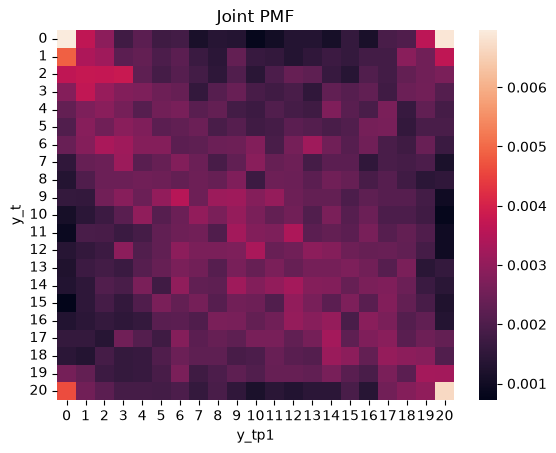

In [16]:
sns.heatmap(tab).set(title='Joint PMF')

[Text(0.5, 1.0, 'Joint PMF minus uniform (1/21**2)')]

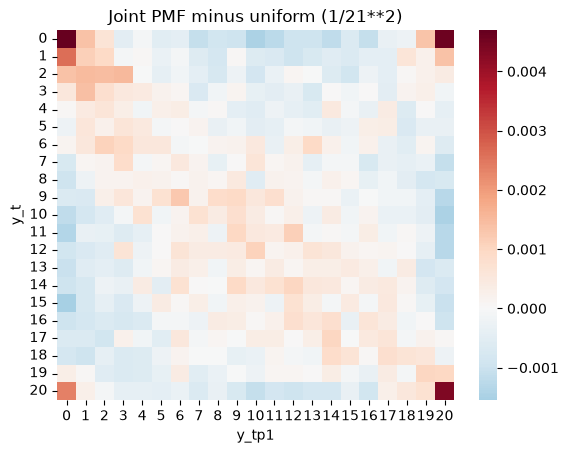

In [17]:
sns.heatmap(tab - 1/21**2, cmap='RdBu_r', center=0).set(title='Joint PMF minus uniform (1/21**2)')

# Do you see any obvious patterns in the joint PMF? 

Yes, most cells are near the uniform value which is 1/441, but the four corners are 2 to 3 times higher. After subtracting 1/21^2, the corners are red, so extreme days tend to be followed by extreme days in either direction. Big moves cluster together, but the direction is random.


- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

In [18]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
tab

y_tp1,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.145817,0.076494,0.061355,0.037450,0.046215,0.036653,0.038247,0.023904,0.028685,0.027888,...,0.021514,0.027888,0.027888,0.023108,0.033466,0.023904,0.040637,0.042231,0.075697,0.144223
1,0.102155,0.071030,0.067039,0.046289,0.048683,0.041500,0.046289,0.035116,0.030327,0.048683,...,0.032721,0.027933,0.031923,0.035914,0.033520,0.038308,0.038308,0.060654,0.052674,0.076616
2,0.074650,0.076983,0.076205,0.077760,0.045879,0.038103,0.043546,0.037325,0.030327,0.041991,...,0.040435,0.048212,0.045879,0.033437,0.027994,0.041991,0.037325,0.047434,0.051322,0.054432
3,0.057813,0.075781,0.063281,0.057031,0.055469,0.050781,0.048438,0.032031,0.043750,0.049219,...,0.036719,0.039844,0.031250,0.046875,0.043750,0.046875,0.036719,0.050000,0.052344,0.042969
4,0.049593,0.057724,0.061789,0.055285,0.045528,0.054472,0.056098,0.046341,0.049593,0.039024,...,0.043902,0.039837,0.037398,0.058537,0.046341,0.041463,0.056911,0.034959,0.048780,0.039837
5,0.044046,0.061175,0.053834,0.061990,0.058728,0.047308,0.048940,0.052202,0.041599,0.045677,...,0.039967,0.047308,0.044861,0.041599,0.044046,0.055465,0.056281,0.033442,0.041599,0.041599
6,0.045952,0.053975,0.064187,0.061269,0.053975,0.053975,0.042305,0.043034,0.046681,0.047411,...,0.037199,0.049599,0.061269,0.048140,0.040846,0.048140,0.037199,0.033552,0.045952,0.032093
7,0.033167,0.051410,0.053068,0.068823,0.047264,0.051410,0.060531,0.053068,0.041459,0.049751,...,0.051410,0.053897,0.040630,0.048093,0.048093,0.033167,0.042289,0.040630,0.043118,0.025705
8,0.029215,0.044240,0.053422,0.053422,0.055092,0.054257,0.050918,0.054257,0.051753,0.060100,...,0.054257,0.053422,0.048414,0.055092,0.051753,0.041736,0.046745,0.039232,0.031720,0.033389


[Text(0.5, 1.0, 'Conditional PMF')]

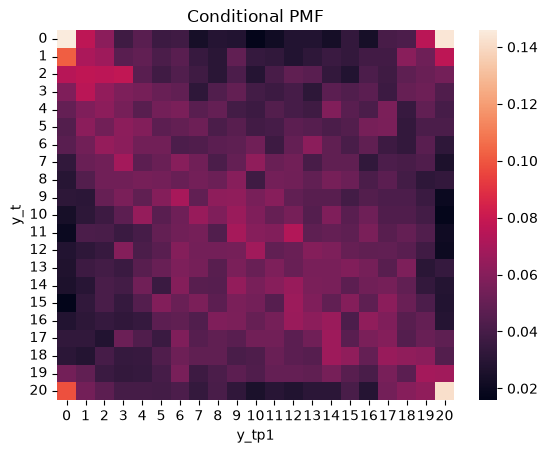

In [19]:
sns.heatmap(tab).set(title='Conditional PMF')

[Text(0.5, 1.0, 'Conditional PMF minus uniform (1/21)')]

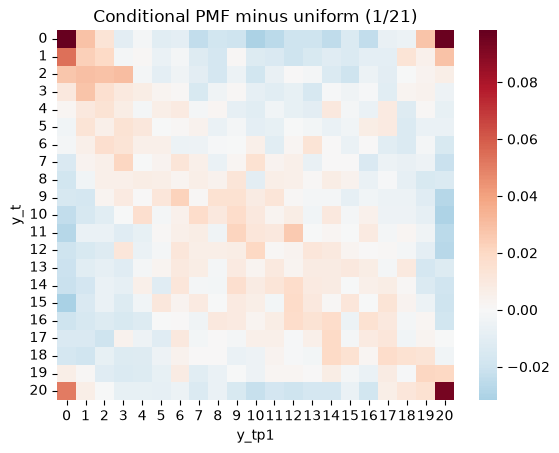

In [20]:
sns.heatmap(tab - 1/21, cmap='RdBu_r', center=0).set(title='Conditional PMF minus uniform (1/21)')

# Do you see any obvious patterns in the conditional PMF?

Yes, the conditional PMF has the same pattern as the joint PMF. After the worst day, there is about a 15% chance tomorrow is also in the worst bin and about 15% that it is in the best bin, compared to 4.8% if it were uniform. The middle rows are close to uniform, so after a normal day tomorrow is hard to predict.

- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

In [21]:
df['market_tp1'] = df['market_return_pct'].shift(-1)
stats = df.groupby('y_t', observed=False)['market_tp1'].describe()
stats

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
0,1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
1,1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
2,1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
3,1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
4,1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
5,1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
6,1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
7,1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
8,1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


[Text(0.5, 1.0, "Next day's min, mean, and max by bin"),
 Text(0.5, 0, 'Bin today (y_t)'),
 Text(0, 0.5, 'Next day return (%)')]

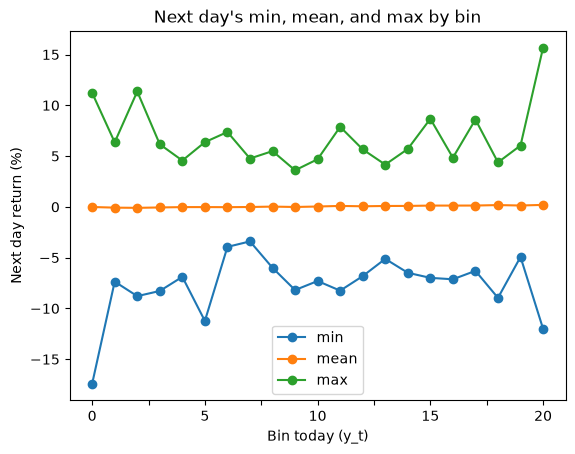

In [22]:
stats[['min', 'mean', 'max']].plot(marker='o').set(title="Next day's min, mean, and max by bin",
    xlabel='Bin today (y_t)', ylabel='Next day return (%)')

# Do you see any obvious patterns?

The min and max are widest after the most extreme bins which is from -17.41 to 11.22 after bin 0, and -12.00 to 15.67 after bin 20. Big days are followed by bigger swings. The mean stays near zero for every bin, going from about -0.1 to 0.2, so today's bin barely changes what tomorrow's return is expected to be.

- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 

[Text(0.5, 1.0, "Next day's standard deviation by bin"),
 Text(0.5, 0, 'Bin today (y_t)'),
 Text(0, 0.5, 'Std of next day return (%)')]

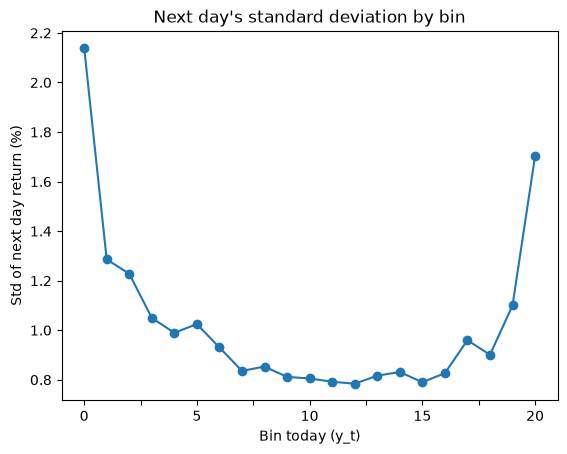

In [23]:
stats['std'].plot(marker='o').set(title="Next day's standard deviation by bin",
    xlabel='Bin today (y_t)', ylabel='Std of next day return (%)')

# Do you see any obvious patterns?

Yes, it makes a U shape. The standard deviation is highest after the extreme bins whcih is 2.14 after bin 0 and 1.70 after bin 20 and lowest in the middle around 
0.8. So tomorrow is much more less predictable after a big day, especially a big loss.

- How easy is it to predict the market?

# How easy is it to predict the market?

It is not easy to predict the market. The mean of tomorrow's return stays near zero for every bin, and outside the extreme bins the conditional PMF is close to uniform, so today's bin does not tell you much about whether tomorrow will be up or down. It is possiblt to slightly predict the size of the move such as after a big day, tomorrow's returns are more spread out. So it is possible to guess how big tomorrow's move might be, but not which direction it will go.